In [ ]:

from pathlib import Path
import warnings, gc, sys, datetime as dt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import openpyxl

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
DATA_DIR = Path.cwd()
OUTPUT_DIR = DATA_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

try:
    import seaborn as sns
    sns.set_theme(style="whitegrid")
except ImportError:
    sns = None

print("Python data-science environment ready.")


Python data-science environment ready.


 Load datasets:

 Dataset Description

The project uses three datasets: AIRQuality_Clean.xlsx for air-quality observations, HOTSPOT_Clean.xlsx for wildfire hotspot information, and Stations.csv for monitoring-station metadata.

 Initial Inspection

The datasets are loaded into pandas DataFrames. Their dimensions, column names, data types, sample records, and missing values are inspected to understand their structure and suitability for analysis.


In [ ]:

aq_path = DATA_DIR / "AIRQuality_Clean.xlsx"
stations_path = DATA_DIR / "Stations.csv"
hotspot_candidates = [DATA_DIR / "HOTSPOT_Clean (1).xlsx", DATA_DIR / "HOTSPOT_Clean.xlsx"]
hotspot_path = next((p for p in hotspot_candidates if p.exists()), None)
if not aq_path.exists():
    raise FileNotFoundError(f"Could not find {aq_path.resolve()}")
if not stations_path.exists():
    raise FileNotFoundError(f"Could not find {stations_path.resolve()}")
if hotspot_path is None:
    raise FileNotFoundError("Could not find HOTSPOT_Clean (1).xlsx or HOTSPOT_Clean.xlsx")

df_aq_raw = pd.read_excel(aq_path, sheet_name="AIR_QUALITY_DATA")
df_stations_raw = pd.read_csv(stations_path, encoding="utf-8-sig")
station_coords = df_stations_raw[["latitude", "longitude"]].to_numpy(dtype=float)
hotspot_workbook = openpyxl.load_workbook(hotspot_path, read_only=True, data_only=True)
hotspot_parts = []

print("Air-quality dataset:", df_aq_raw.shape)
print("Station metadata:", df_stations_raw.shape)
display(df_aq_raw.head())
display(df_stations_raw)


Air-quality dataset: (524603, 9)
Station metadata: (6, 3)


,Source.Name,Date,Time,Wind_Direction,TEMP,Wind_speed,PM25,HUMIDITY,RAINFALL
0,Earlwood,2016-01-01,01:00,256.9,18.7,0.2,28.9,83.4,
1,Earlwood,2016-01-01,02:00,242.7,18.0,0.1,31.2,88.6,
2,Earlwood,2016-01-01,03:00,282.0,17.8,0.2,18.7,90.6,
3,Earlwood,2016-01-01,04:00,271.2,17.4,0.2,6.1,92.2,
4,Earlwood,2016-01-01,05:00,293.8,16.9,0.2,4.2,93.9,


,station,latitude,longitude
0,Richmond,-33.618,150.751
1,Liverpool,-33.920,150.924
2,Wyong,-33.149,151.488
3,Wollongong,-34.430,150.880
4,Newcastle,-32.928,151.782
5,Earlwood,-33.910,151.110


In [ ]:

def read_hotspot_sheet_near_stations(sheet_name):
    ws = hotspot_workbook[sheet_name]
    kept, batch = [], []
    scanned = 0
    station_lat = np.radians(station_coords[:, 0])[None, :]
    station_lon = np.radians(station_coords[:, 1])[None, :]

    def filter_batch(rows):
        arr = np.array([
            [r[1] if isinstance(r[1], (int, float)) else np.nan,
             r[2] if isinstance(r[2], (int, float)) else np.nan,
             r[4] if isinstance(r[4], (int, float)) else np.nan]
            for r in rows
        ], dtype=float)
        coarse = (np.isfinite(arr).all(axis=1) & (arr[:, 2] > 0) &
                  (arr[:, 0] >= -39.5) & (arr[:, 0] <= -27.5) &
                  (arr[:, 1] >= 143.5) & (arr[:, 1] <= 158.5))
        if not coarse.any():
            return []
        pos = np.where(coarse)[0]
        lat = np.radians(arr[pos, 0])[:, None]
        lon = np.radians(arr[pos, 1])[:, None]
        dlat, dlon = station_lat - lat, station_lon - lon
        a = np.sin(dlat / 2)**2 + np.cos(lat) * np.cos(station_lat) * np.sin(dlon / 2)**2
        distances = 6371.0 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
        valid_pos = pos[(distances <= 500).any(axis=1)]
        return [rows[j] for j in valid_pos if isinstance(rows[j][6], dt.datetime)]

    for row in ws.iter_rows(min_row=2, values_only=True):
        batch.append(row)
        scanned += 1
        if len(batch) >= 50000:
            kept.extend(filter_batch(batch))
            batch = []
    if batch:
        kept.extend(filter_batch(batch))
    print(f"{sheet_name}: scanned {scanned:,} rows; retained {len(kept):,} detections within 500 km of at least one station.")
    return kept

print("Streaming hotspot reader configured; nearby detections are retained for station-level fire features.")


Streaming hotspot reader configured; nearby detections are retained for station-level fire features.


In [ ]:
hotspot_parts.append(read_hotspot_sheet_near_stations("Hotspot_2016-2018"))

Hotspot_2016-2018: scanned 31,857 rows; retained 28,815 detections within 500 km of at least one station.


In [ ]:
hotspot_parts.append(read_hotspot_sheet_near_stations("Hotspot_2019-2020"))

Hotspot_2019-2020: scanned 600,000 rows; retained 581,088 detections within 500 km of at least one station.


In [ ]:
hotspot_parts.append(read_hotspot_sheet_near_stations("Hotspot_2021-2022"))

Hotspot_2021-2022: scanned 626,368 rows; retained 548,496 detections within 500 km of at least one station.


In [ ]:
hotspot_parts.append(read_hotspot_sheet_near_stations("Hotspot_2023-2025"))

Hotspot_2023-2025: scanned 1,048,575 rows; retained 910,959 detections within 500 km of at least one station.


In [ ]:

hotspot_columns = ["Source.Name", "latitude", "longitude", "temp_kelvin", "power", "confidence", "datetime"]
from itertools import chain
df_hot_raw = pd.DataFrame.from_records(chain.from_iterable(hotspot_parts), columns=hotspot_columns)
hotspot_workbook.close()
del hotspot_parts
gc.collect()
print("Station-local hotspot records loaded:", f"{len(df_hot_raw):,}")
print("Columns:", list(df_hot_raw.columns))


Station-local hotspot records loaded: 2,069,358
Columns: ['Source.Name', 'latitude', 'longitude', 'temp_kelvin', 'power', 'confidence', 'datetime']


 Data cleaning


Missing Values and Duplicates *italicized text*

Missing values, duplicate records, and invalid measurements are examined and handled according to their relevance to the analysis. Missing measurements are not automatically treated as zero pollution or zero fire activity.
 Data Type Correction

Date and time columns are converted into consistent datetime formats, while numerical variables are converted to appropriate numeric types.

Data Quality

Data-quality checks help identify limitations that could affect the reliability of the analysis and subsequent predictions.


In [ ]:
def audit_table(df, name):
    print(f"\n{name}: {df.shape[0]:,} rows × {df.shape[1]} columns")
    display(pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing_n": df.isna().sum(),
        "missing_pct": (100 * df.isna().mean()).round(2),
        "n_unique": df.nunique(dropna=True)
    }))
    print("Exact duplicate rows:", int(df.duplicated().sum()))

audit_table(df_aq_raw, "Raw air quality")
audit_table(df_stations_raw, "Raw stations")
audit_table(df_hot_raw, "Raw hotspots")


Raw air quality: 524,603 rows × 9 columns
Exact duplicate rows: 8769

Raw stations: 6 rows × 3 columns
Exact duplicate rows: 0

Raw hotspots: 2,069,358 rows × 7 columns
Exact duplicate rows: 345332


,dtype,missing_n,missing_pct,n_unique
Source.Name,object,0,0.00,6
Date,datetime64[ns],8771,1.67,3653
Time,object,0,0.00,26
Wind_Direction,float64,13626,2.60,3601
TEMP,float64,16046,3.06,493
Wind_speed,float64,13647,2.60,122
PM25,object,37563,7.16,1449
HUMIDITY,float64,20679,3.94,1026
RAINFALL,object,0,0.00,153


,dtype,missing_n,missing_pct,n_unique
station,object,0,0.0,6
latitude,float64,0,0.0,6
longitude,float64,0,0.0,6


,dtype,missing_n,missing_pct,n_unique
Source.Name,object,0,0.0,12
latitude,float64,0,0.0,88352
longitude,float64,0,0.0,79780
temp_kelvin,float64,0,0.0,14145
power,float64,0,0.0,2600
confidence,int64,0,0.0,101
datetime,datetime64[ns],0,0.0,201389


In [ ]:
df_aq = df_aq_raw.copy()
df_aq.columns = df_aq.columns.astype(str).str.strip()
rename_map = {
    "Source.Name": "station", "Wind_Direction": "wind_direction",
    "TEMP": "temp", "Wind_speed": "wind_speed", "Wind_Speed": "wind_speed",
    "PM25": "pm25", "HUMIDITY": "humidity", "RAINFALL": "rainfall"
}
df_aq = df_aq.rename(columns={k:v for k,v in rename_map.items() if k in df_aq.columns})
required = {"station", "Date", "Time", "pm25"}
missing_required = required - set(df_aq.columns)
if missing_required:
    raise ValueError(f"Air-quality dataset is missing required columns: {missing_required}")

df_aq["station"] = df_aq["station"].astype("string").str.strip().str.title()
date_text = pd.to_datetime(df_aq["Date"], errors="coerce", dayfirst=True).dt.strftime("%Y-%m-%d")
time_text = df_aq["Time"].astype("string").str.strip()
is_24 = time_text.str.match(r"^24:00(?::00(?:\.0+)?)?$", na=False)
time_fixed = time_text.mask(is_24, "00:00:00")
df_aq["datetime"] = pd.to_datetime(date_text + " " + time_fixed, errors="coerce")
df_aq.loc[is_24 & df_aq["datetime"].notna(), "datetime"] += pd.Timedelta(days=1)
df_aq = df_aq.dropna(subset=["station", "datetime"]).copy()

numeric_cols = ["wind_direction", "temp", "wind_speed", "pm25", "humidity", "rainfall"]
for col in numeric_cols:
    if col in df_aq.columns:
        df_aq[col] = pd.to_numeric(df_aq[col], errors="coerce")

df_aq = df_aq.sort_values(["station", "datetime"])
before = len(df_aq)
df_aq = df_aq.drop_duplicates(["station", "datetime"], keep="first").reset_index(drop=True)
print(f"Removed {before-len(df_aq):,} duplicate station-hour records.")
df_aq["pm25_observed"] = df_aq["pm25"]  # preserve observed values for target creation

df_stations = df_stations_raw.copy()
df_stations.columns = df_stations.columns.astype(str).str.strip()
df_stations = df_stations.rename(columns={"Station":"station", "Latitude":"latitude", "Longitude":"longitude"})
df_stations["station"] = df_stations["station"].astype("string").str.strip().str.title()
for col in ["latitude", "longitude"]:
    df_stations[col] = pd.to_numeric(df_stations[col], errors="coerce")
df_stations = df_stations.dropna(subset=["station", "latitude", "longitude"]).drop_duplicates("station")
df_stations = df_stations[df_stations["latitude"].between(-45, -10) & df_stations["longitude"].between(110, 155)]

print("Clean air quality:", df_aq.shape)
print("Station metadata:", df_stations.shape)
display(df_aq.head())
display(df_stations)

Removed 0 duplicate station-hour records.
Clean air quality: (494339, 11)
Station metadata: (6, 3)


,station,Date,Time,wind_direction,temp,wind_speed,pm25,humidity,rainfall,datetime,pm25_observed
0,Earlwood,2016-01-01,01:00,256.9,18.7,0.2,28.9,83.4,NaN,2016-01-01 01:00:00,28.9
1,Earlwood,2016-01-01,02:00,242.7,18.0,0.1,31.2,88.6,NaN,2016-01-01 02:00:00,31.2
2,Earlwood,2016-01-01,03:00,282.0,17.8,0.2,18.7,90.6,NaN,2016-01-01 03:00:00,18.7
3,Earlwood,2016-01-01,04:00,271.2,17.4,0.2,6.1,92.2,NaN,2016-01-01 04:00:00,6.1
4,Earlwood,2016-01-01,05:00,293.8,16.9,0.2,4.2,93.9,NaN,2016-01-01 05:00:00,4.2


,station,latitude,longitude
0,Richmond,-33.618,150.751
1,Liverpool,-33.920,150.924
2,Wyong,-33.149,151.488
3,Wollongong,-34.430,150.880
4,Newcastle,-32.928,151.782
5,Earlwood,-33.910,151.110


In [ ]:
quality_rows = []
for station, part in df_aq.groupby("station"):
    quality_rows.append({
        "station": station, "rows": len(part),
        "start": part["datetime"].min(), "end": part["datetime"].max(),
        "pm25_missing_pct": 100 * part["pm25_observed"].isna().mean(),
        "temperature_missing_pct": 100 * part["temp"].isna().mean(),
        "humidity_missing_pct": 100 * part["humidity"].isna().mean(),
        "duplicate_station_hours_after_cleaning": int(part.duplicated(["datetime"]).sum())
    })
df_station_quality = pd.DataFrame(quality_rows).sort_values("station")
display(df_station_quality.round(2))

,station,rows,start,end,pm25_missing_pct,temperature_missing_pct,humidity_missing_pct,duplicate_station_hours_after_cleaning
0,Earlwood,83329,2016-01-01 01:00:00,2025-12-31 23:00:00,2.66,1.60,1.63,0
1,Liverpool,84019,2016-01-01 01:00:00,2025-12-31 23:00:00,4.95,1.22,1.24,0
2,Newcastle,84019,2016-01-01 01:00:00,2025-12-31 23:00:00,5.34,1.36,4.43,0
3,Richmond,75624,2016-01-01 01:00:00,2025-12-31 23:00:00,8.35,1.71,1.74,0
4,Wollongong,83329,2016-01-01 01:00:00,2025-12-31 23:00:00,7.51,1.42,3.60,0
5,Wyong,84019,2016-01-01 01:00:00,2025-12-31 23:00:00,5.45,1.14,1.11,0


In [ ]:
df_hot = df_hot_raw.copy()
df_hot.columns = df_hot.columns.astype(str).str.strip()
df_hot = df_hot.rename(columns={"Source.Name":"source_name", "datetime":"datetime"})
for col in ["latitude", "longitude", "temp_kelvin", "power", "confidence"]:
    if col in df_hot.columns:
        df_hot[col] = pd.to_numeric(df_hot[col], errors="coerce")
df_hot["datetime"] = pd.to_datetime(df_hot["datetime"], errors="coerce")
n_before = len(df_hot)
df_hot = df_hot.dropna(subset=["latitude", "longitude", "datetime", "power"])
df_hot = df_hot[df_hot["power"] > 0]
df_hot = df_hot[df_hot["latitude"].between(-45, -10) & df_hot["longitude"].between(110, 155)]
df_hot = df_hot.drop_duplicates(subset=["latitude", "longitude", "datetime", "power"])
df_hot["hour"] = df_hot["datetime"].dt.floor("h")
df_hot = df_hot.sort_values("datetime").reset_index(drop=True)
print(f"Hotspots retained: {len(df_hot):,} / {n_before:,} ({100*len(df_hot)/max(n_before,1):.1f}%).")
print("Hotspot time range:", df_hot["datetime"].min(), "to", df_hot["datetime"].max())
display(df_hot[["latitude","longitude","datetime","power","confidence"]].describe().round(2))

Hotspots retained: 1,723,942 / 2,069,358 (83.3%).
Hotspot time range: 2016-01-02 03:56:10 to 2025-07-14 06:18:21


,latitude,longitude,datetime,power,confidence
count,1723942.00,1723942.00,1723942,1723942.00,1723942.00
mean,-32.35,149.81,2021-11-02 03:46:44.757971968,39.96,54.12
min,-37.49,145.36,2016-01-02 03:56:10,0.10,0.00
25%,-34.23,147.79,2019-12-02 14:48:30,5.30,9.00
50%,-32.19,150.14,2021-04-12 04:00:56,17.20,50.00
75%,-30.52,152.01,2023-10-16 04:09:11,50.90,80.00
max,-28.44,153.61,2025-07-14 06:18:21,260.00,100.00
std,2.24,2.23,NaN,52.84,31.95


Data merging

* Dataset Integration 

The cleaned air-quality, hotspot, and station datasets are combined using the available station identifiers, timestamps, and geographical information where appropriate.

* Validation

The merged dataset is checked for duplicate records, missing matches, and unexpected changes in row counts. Matching procedures should avoid incorrectly assigning fire activity to stations or introducing future information into predictors.


In [ ]:

df_station_context = df_aq.merge(df_stations[["station","latitude","longitude"]], on="station", how="left", validate="many_to_one")
print("Air-quality rows after station metadata merge:", f"{len(df_station_context):,}")
print("Rows without station coordinates:", int(df_station_context["latitude"].isna().sum()))
display(df_station_context[["station","datetime","pm25_observed","latitude","longitude"]].head())


Air-quality rows after station metadata merge: 494,339
Rows without station coordinates: 0


,station,datetime,pm25_observed,latitude,longitude
0,Earlwood,2016-01-01 01:00:00,28.9,-33.91,151.11
1,Earlwood,2016-01-01 02:00:00,31.2,-33.91,151.11
2,Earlwood,2016-01-01 03:00:00,18.7,-33.91,151.11
3,Earlwood,2016-01-01 04:00:00,6.1,-33.91,151.11
4,Earlwood,2016-01-01 05:00:00,4.2,-33.91,151.11


In [ ]:
def haversine_km(lat1, lon1, lat2, lon2):
    r = 6371.0
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat, dlon = lat2-lat1, lon2-lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
    return 2*r*np.arcsin(np.sqrt(np.clip(a, 0, 1)))

def fire_features_for_station(station_row, hotspot_df, aq_times):
    station = station_row["station"]
    lat, lon = float(station_row["latitude"]), float(station_row["longitude"])
    # Broad spatial pre-filter (roughly several hundred kilometres).
    local = hotspot_df[
        hotspot_df["latitude"].between(lat-5.0, lat+5.0) &
        hotspot_df["longitude"].between(lon-7.0, lon+7.0)
    ].copy()
    if local.empty:
        result = pd.DataFrame(index=pd.DatetimeIndex(aq_times.unique()).sort_values())
        result.index.name = "datetime"
        for band in [50,100,200,500]:
            result[f"fires_{band}km_24h"] = 0.0
            result[f"frp_{band}km_24h"] = 0.0
        result["nearest_fire_km_24h"] = np.nan
        return result.reset_index()
    local["distance_km"] = haversine_km(lat, lon, local["latitude"].to_numpy(), local["longitude"].to_numpy())
    local = local[local["distance_km"] <= 500].copy()
    if local.empty:
        return fire_features_for_station(station_row, hotspot_df.iloc[0:0], aq_times)
    local["hour"] = local["datetime"].dt.floor("h")
    local["frp"] = pd.to_numeric(local["power"], errors="coerce").fillna(0)
    local["count"] = 1
    grouped = {}
    for band in [50,100,200,500]:
        subset = local[local["distance_km"] <= band]
        g = subset.groupby("hour").agg(**{
            f"fires_{band}km": ("count","sum"),
            f"frp_{band}km": ("frp","sum")
        })
        grouped[band] = g
    hourly = pd.concat([v for v in grouped.values()], axis=1).fillna(0).sort_index()
    full_index = pd.date_range(min(pd.to_datetime(aq_times).min(), hourly.index.min()),
                               max(pd.to_datetime(aq_times).max(), hourly.index.max()), freq="h")
    hourly = hourly.reindex(full_index, fill_value=0)
    hourly.index.name = "datetime"
    # For each observation at t, use detections from [t-24h, t-1h].
    for band in [50,100,200,500]:
        for metric in ["fires", "frp"]:
            col = f"{metric}_{band}km"
            hourly[f"{col}_24h"] = hourly[col].rolling(24, min_periods=1).sum().shift(1).fillna(0)
    nearest = local.groupby("hour")["distance_km"].min().reindex(full_index)
    hourly["nearest_fire_km_24h"] = nearest.rolling(24, min_periods=1).min().shift(1)
    keep = [f"{m}_{b}km_24h" for b in [50,100,200,500] for m in ["fires","frp"]] + ["nearest_fire_km_24h"]
    return hourly[keep].reset_index()

# Build features for the stations present in both datasets.
station_names = set(df_aq["station"].dropna().unique())
station_meta = df_stations[df_stations["station"].isin(station_names)]
fire_feature_frames = []
for _, station_row in station_meta.iterrows():
    print("Matching hotspot history for", station_row["station"])
    fire_df = fire_features_for_station(station_row, df_hot, df_aq.loc[df_aq["station"] == station_row["station"], "datetime"])
    fire_df["station"] = station_row["station"]
    fire_feature_frames.append(fire_df)

df_fire_features = pd.concat(fire_feature_frames, ignore_index=True) if fire_feature_frames else pd.DataFrame()
print("Fire feature rows:", len(df_fire_features))
display(df_fire_features.head())

Matching hotspot history for Richmond
Matching hotspot history for Liverpool
Matching hotspot history for Wyong
Matching hotspot history for Wollongong
Matching hotspot history for Newcastle
Matching hotspot history for Earlwood
Fire feature rows: 526026


,datetime,fires_50km_24h,frp_50km_24h,fires_100km_24h,frp_100km_24h,fires_200km_24h,frp_200km_24h,fires_500km_24h,frp_500km_24h,nearest_fire_km_24h,station
0,2016-01-01 01:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,Richmond
1,2016-01-01 02:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,Richmond
2,2016-01-01 03:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,Richmond
3,2016-01-01 04:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,Richmond
4,2016-01-01 05:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,Richmond


Exploratory data analysis

Air-Quality Patterns

Descriptive statistics and visualisations are used to examine PM₂.₅ distributions, variation over time, and extreme observations.

Wildfire Activity

Hotspot observations are analysed to identify temporal patterns in detected fire activity.

Relationship Between Variables

Air-quality and hotspot patterns are compared to investigate potential associations. These relationships may be influenced by weather, wind direction, smoke transport, and other pollution sources; therefore, association does not establish causation.


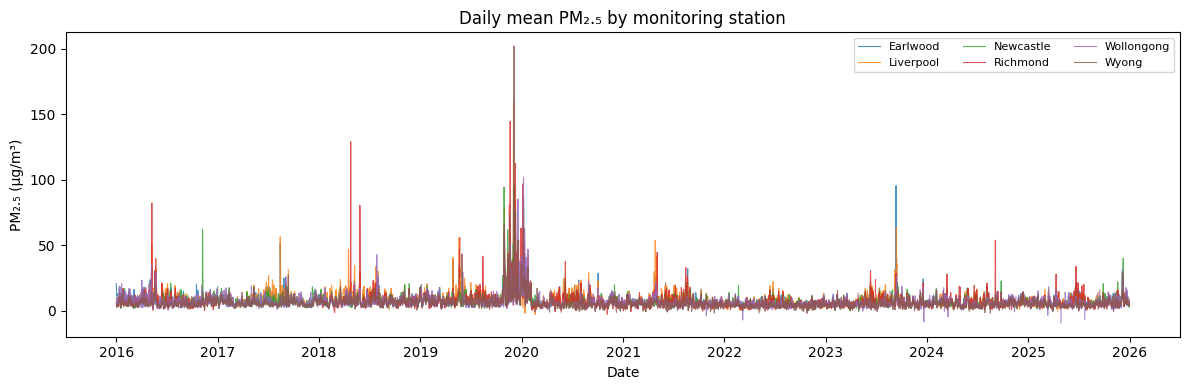

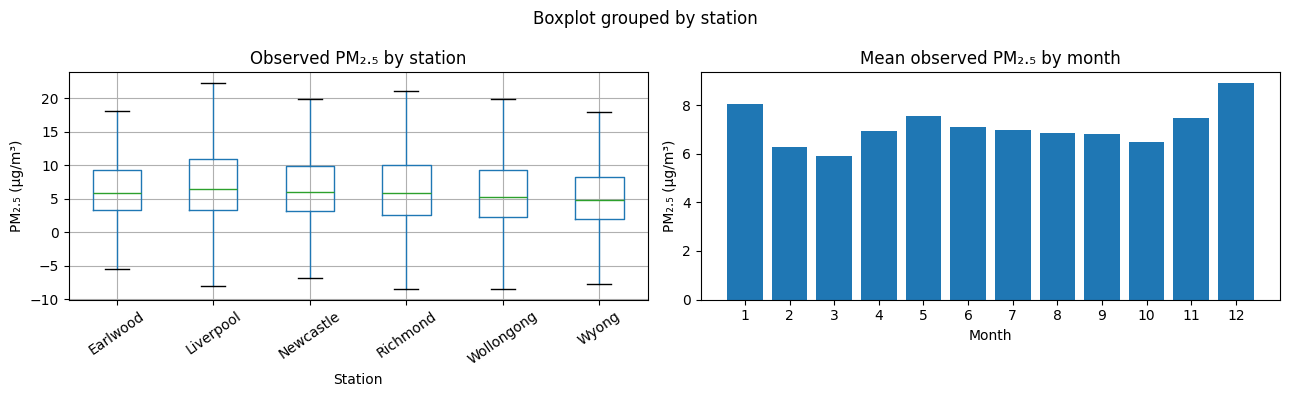

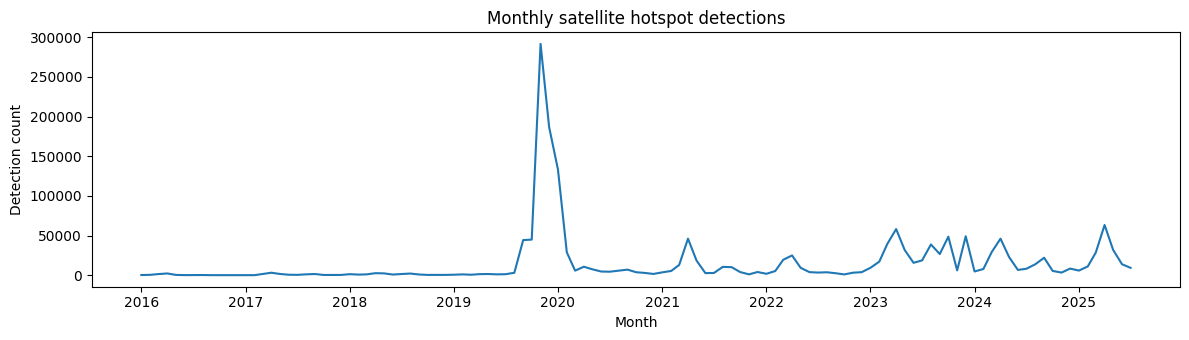

In [ ]:
fig, ax = plt.subplots(figsize=(12, 4))
for station, part in df_aq.groupby("station"):
    daily = part.set_index("datetime")["pm25_observed"].resample("D").mean()
    ax.plot(daily.index, daily.values, linewidth=0.8, alpha=0.8, label=station)
ax.set(title="Daily mean PM₂.₅ by monitoring station", xlabel="Date", ylabel="PM₂.₅ (µg/m³)")
ax.legend(ncol=3, fontsize=8)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df_aq.boxplot(column="pm25_observed", by="station", ax=axes[0], showfliers=False)
axes[0].set_title("Observed PM₂.₅ by station")
axes[0].set_xlabel("Station"); axes[0].set_ylabel("PM₂.₅ (µg/m³)")
axes[0].tick_params(axis="x", rotation=35)
df_aq["month"] = df_aq["datetime"].dt.month
monthly = df_aq.groupby("month")["pm25_observed"].mean()
axes[1].bar(monthly.index, monthly.values)
axes[1].set(title="Mean observed PM₂.₅ by month", xlabel="Month", ylabel="PM₂.₅ (µg/m³)")
axes[1].set_xticks(range(1,13))
fig.tight_layout()
plt.show()

hot_monthly = df_hot.set_index("datetime").resample("MS").size()
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(hot_monthly.index, hot_monthly.values)
ax.set(title="Monthly satellite hotspot detections", xlabel="Month", ylabel="Detection count")
fig.tight_layout()
plt.show()

Black Summer case study:

Case Study Purpose
The Black Summer bushfire period provides a historical example for examining changes in Australian air quality during significant wildfire activity.

Period Comparison
PM₂.₅ observations are compared across the selected periods before, during, and after the event. The calculated statistics are used to identify differences

,period,AQ records,valid PM2.5 records,mean PM2.5 (µg/m³),95th percentile PM2.5,hotspot detections
0,Before (Oct 2018–Mar 2019),25116,23436,7.62,17.60,3032
1,Black Summer (Oct 2019–Mar 2020),25254,23139,15.29,55.01,691188
2,After (Oct 2020–Mar 2021),25116,23999,5.84,15.50,29727


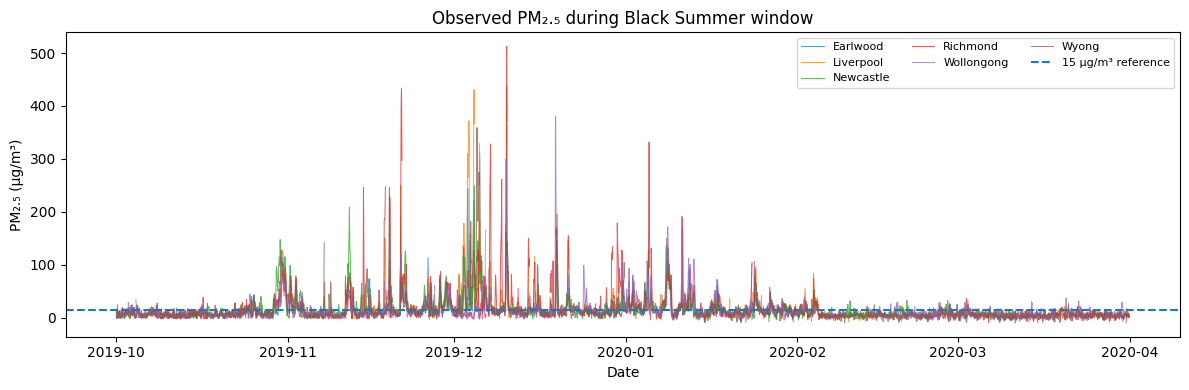

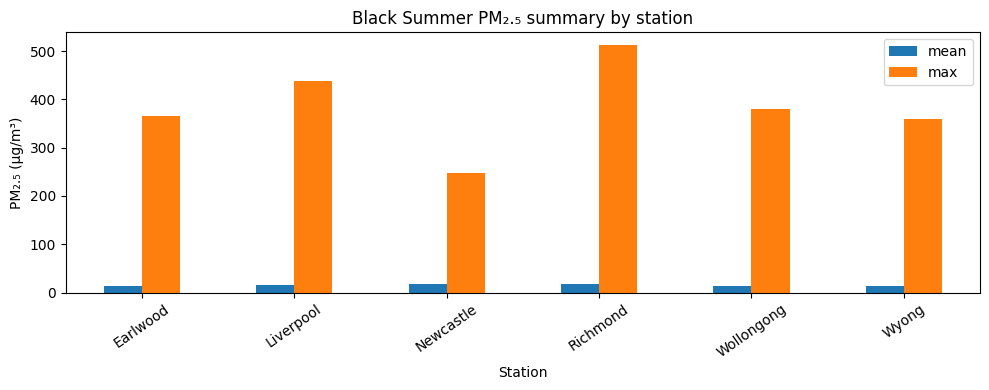

In [ ]:
black_start, black_end = pd.Timestamp("2019-10-01"), pd.Timestamp("2020-04-01")
periods = [
    ("Before (Oct 2018–Mar 2019)", pd.Timestamp("2018-10-01"), pd.Timestamp("2019-04-01")),
    ("Black Summer (Oct 2019–Mar 2020)", black_start, black_end),
    ("After (Oct 2020–Mar 2021)", pd.Timestamp("2020-10-01"), pd.Timestamp("2021-04-01"))
]
period_rows = []
for label, start, end in periods:
    aq_part = df_aq[(df_aq["datetime"] >= start) & (df_aq["datetime"] < end)]
    hot_part = df_hot[(df_hot["datetime"] >= start) & (df_hot["datetime"] < end)]
    period_rows.append({
        "period": label, "AQ records": len(aq_part),
        "valid PM2.5 records": int(aq_part["pm25_observed"].notna().sum()),
        "mean PM2.5 (µg/m³)": aq_part["pm25_observed"].mean(),
        "95th percentile PM2.5": aq_part["pm25_observed"].quantile(.95),
        "hotspot detections": len(hot_part)
    })
df_black_summer_summary = pd.DataFrame(period_rows)
display(df_black_summer_summary.round(2))

fig, ax = plt.subplots(figsize=(12, 4))
bs = df_aq[(df_aq["datetime"] >= "2019-10-01") & (df_aq["datetime"] < "2020-04-01")]
for station, part in bs.groupby("station"):
    ax.plot(part["datetime"], part["pm25_observed"], linewidth=0.7, alpha=0.75, label=station)
ax.axhline(15, linestyle="--", label="15 µg/m³ reference")
ax.set(title="Observed PM₂.₅ during Black Summer window", xlabel="Date", ylabel="PM₂.₅ (µg/m³)")
ax.legend(ncol=3, fontsize=8)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
if not bs.empty:
    by_station = bs.groupby("station")["pm25_observed"].agg(["mean","max"])
    by_station.plot(kind="bar", ax=ax)
    ax.set(title="Black Summer PM₂.₅ summary by station", xlabel="Station", ylabel="PM₂.₅ (µg/m³)")
    ax.tick_params(axis="x", rotation=35)
fig.tight_layout()
plt.show()

Black Summer visualisations:

Time-Series Analysis

Time-series plots illustrate changes in PM₂.₅ during the selected case-study period and help identify pollution peaks.

Interpretation

Visual comparisons highlight temporal variation in air quality. Individual peaks should not automatically be attributed to specific fires without additional evidence about fire activity and atmospheric conditions.


station,Earlwood,Liverpool,Newcastle,Richmond,Wollongong,Wyong
month,,,,,,
2019-10,10.06,11.64,13.91,11.22,10.11,11.22
2019-11,16.62,18.70,22.28,26.22,15.79,19.92
2019-12,24.52,33.78,24.11,31.90,18.25,27.75
2020-01,19.20,20.06,18.15,21.88,23.94,15.88
2020-02,5.91,6.95,7.10,5.88,6.80,5.74
2020-03,4.54,5.92,6.43,4.65,5.37,4.11


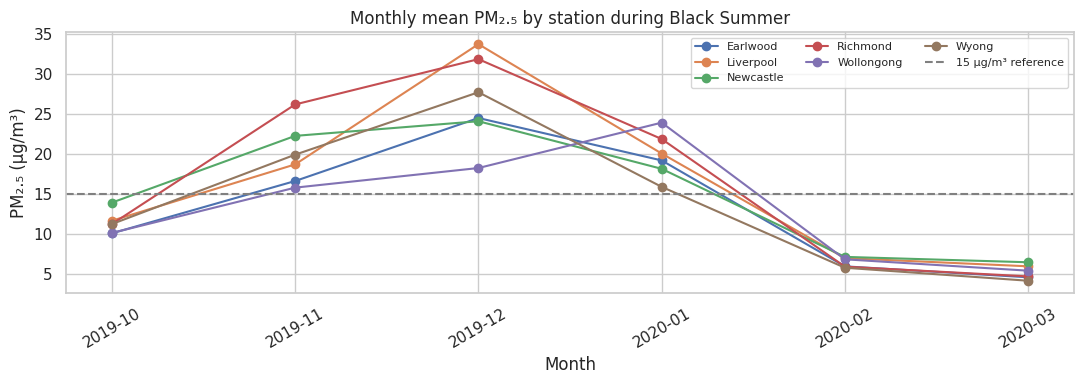

In [ ]:

bs_monthly = df_aq[(df_aq["datetime"] >= "2019-10-01") & (df_aq["datetime"] < "2020-04-01")].copy()
bs_monthly["month"] = bs_monthly["datetime"].dt.to_period("M").astype(str)
bs_monthly_summary = bs_monthly.groupby(["month","station"])["pm25_observed"].mean().reset_index()
display(bs_monthly_summary.pivot(index="month",columns="station",values="pm25_observed").round(2))
fig, ax = plt.subplots(figsize=(11, 4))
for station, part in bs_monthly_summary.groupby("station"):
    ax.plot(part["month"], part["pm25_observed"], marker="o", label=station)
ax.axhline(15.0, linestyle="--", color="grey", label="15 µg/m³ reference")
ax.set(title="Monthly mean PM₂.₅ by station during Black Summer", xlabel="Month", ylabel="PM₂.₅ (µg/m³)")
ax.tick_params(axis="x", rotation=30); ax.legend(ncol=3, fontsize=8)
fig.tight_layout(); plt.show()


Station-level analysis:


Station Comparisons

PM₂.₅ observations are summarised by monitoring station to investigate differences in pollution levels and observation coverage.

Spatial Interpretation

Station metadata provide geographical context for the observed measurements. Comparisons must consider missing data, differences in monitoring periods, and uneven station coverage.


,station,observations,mean_pm25,median_pm25,p95_pm25,max_pm25,exceedance_hours,missing_pm25,exceedance_pct
0,Earlwood,81110,7.30,5.8,18.3,495.1,6740,2219,8.31
1,Liverpool,79859,8.34,6.5,21.9,437.1,10497,4160,13.14
2,Newcastle,79533,7.28,6.0,18.3,248.3,7105,4486,8.93
3,Richmond,69313,7.46,5.8,19.9,513.0,7171,6311,10.35
4,Wollongong,77069,6.60,5.3,18.1,380.3,6714,6260,8.71
5,Wyong,79444,5.81,4.8,15.7,359.1,4493,4575,5.66


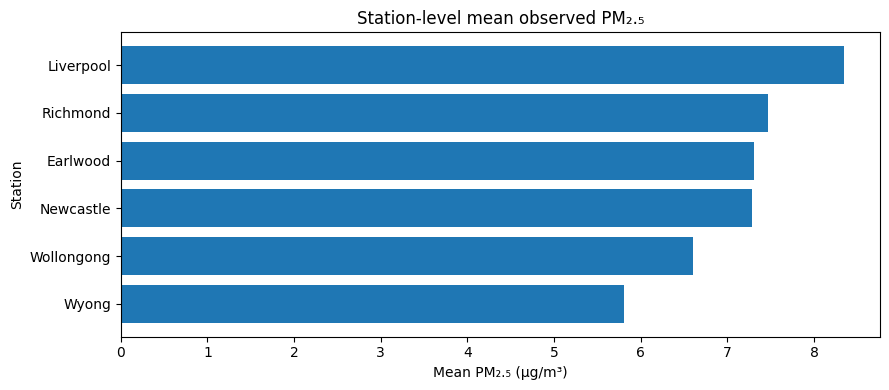

In [ ]:

station_summary = df_aq.groupby("station").agg(
    observations=("pm25_observed", "count"),
    mean_pm25=("pm25_observed", "mean"),
    median_pm25=("pm25_observed", "median"),
    p95_pm25=("pm25_observed", lambda s: s.quantile(0.95)),
    max_pm25=("pm25_observed", "max"),
    exceedance_hours=("pm25_observed", lambda s: int((s > 15.0).sum())),
    missing_pm25=("pm25_observed", lambda s: int(s.isna().sum()))
).reset_index()
station_summary["exceedance_pct"] = 100 * station_summary["exceedance_hours"] / station_summary["observations"].replace(0, np.nan)
display(station_summary.round(2))
fig, ax = plt.subplots(figsize=(9, 4))
plot_summary = station_summary.sort_values("mean_pm25")
ax.barh(plot_summary["station"], plot_summary["mean_pm25"])
ax.set(title="Station-level mean observed PM₂.₅", xlabel="Mean PM₂.₅ (µg/m³)", ylabel="Station")
fig.tight_layout()
plt.show()


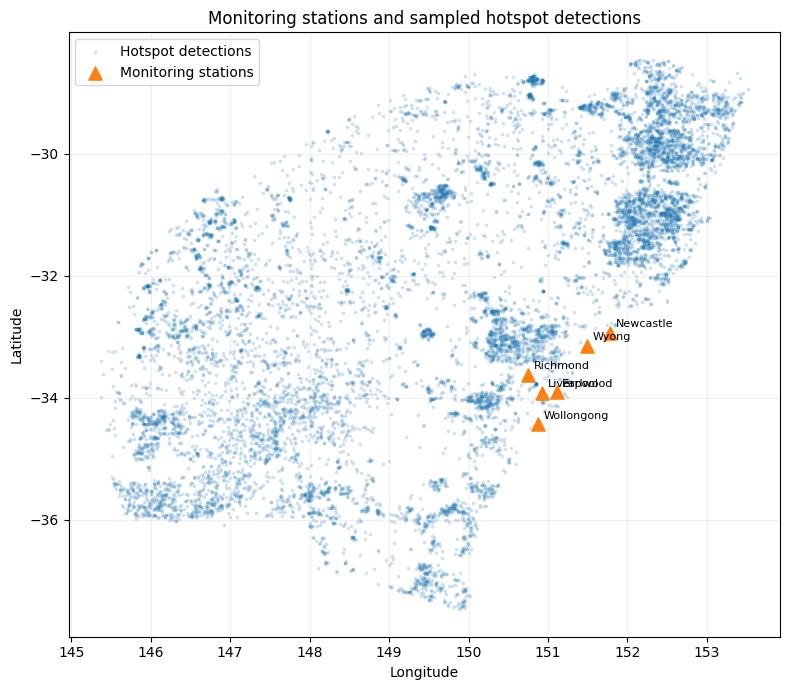

In [ ]:
fig, ax = plt.subplots(figsize=(8, 7))
plot_hot = df_hot.sample(min(12000, len(df_hot)), random_state=RANDOM_STATE) if len(df_hot) else df_hot
if len(plot_hot):
    ax.scatter(plot_hot["longitude"], plot_hot["latitude"], s=3, alpha=0.15, label="Hotspot detections")
ax.scatter(df_stations["longitude"], df_stations["latitude"], marker="^", s=90, label="Monitoring stations")
for _, row in df_stations.iterrows():
    ax.annotate(row["station"], (row["longitude"], row["latitude"]), xytext=(4,4), textcoords="offset points", fontsize=8)
ax.set(title="Monitoring stations and sampled hotspot detections", xlabel="Longitude", ylabel="Latitude")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

Feature engineering:

Predictive Features

Features are derived from available temporal information, historical air-quality observations, and wildfire hotspot activity. These variables help models identify patterns associated with future PM₂.₅ exceedances.

Data Leakage Prevention

Predictors must contain only information available at the prediction time. Lagged measurements and rolling statistics must use past observations only. Future PM₂.₅ measurements may define the target but must not be used as predictors.


In [ ]:
# Preserve hotspot coverage end so dashboard predictions do not assume future satellite data exists.
HOTSPOT_DATA_END = df_hot["datetime"].max()

# Join station metadata and time-matched fire features.
df_model = df_aq.merge(df_stations[["station","latitude","longitude"]], on="station", how="left")
if not df_fire_features.empty:
    df_model = df_model.merge(df_fire_features, on=["station","datetime"], how="left")
else:
    for band in [50,100,200,500]:
        df_model[f"fires_{band}km_24h"] = 0.0
        df_model[f"frp_{band}km_24h"] = 0.0
    df_model["nearest_fire_km_24h"] = np.nan

fire_cols = [c for c in df_model.columns if c.startswith(("fires_","frp_")) and c.endswith("_24h")]
df_model[fire_cols] = df_model[fire_cols].fillna(0)

# Keep observed PM₂.₅ unchanged for target creation; predictor history uses past-only forward-fill.
df_model = df_model.sort_values(["station","datetime"]).reset_index(drop=True)
df_model["pm25_predictor"] = df_model.groupby("station")["pm25_observed"].transform(
    lambda s: s.ffill(limit=3)
)

for lag in [1,3,6,12,24]:
    df_model[f"pm25_lag_{lag}h"] = df_model.groupby("station")["pm25_predictor"].shift(lag)
for window in [6,12,24]:
    df_model[f"pm25_mean_prev_{window}h"] = df_model.groupby("station")["pm25_predictor"].transform(
        lambda s: s.shift(1).rolling(window, min_periods=max(2, window//2)).mean()
    )
df_model["temp_prev"] = df_model.groupby("station")["temp"].shift(1)
df_model["humidity_prev"] = df_model.groupby("station")["humidity"].shift(1)
df_model["wind_speed_prev"] = df_model.groupby("station")["wind_speed"].shift(1)
df_model["rainfall_prev"] = df_model.groupby("station")["rainfall"].shift(1)
df_model["wind_direction_prev"] = df_model.groupby("station")["wind_direction"].shift(1)
df_model["hour"] = df_model["datetime"].dt.hour
df_model["month"] = df_model["datetime"].dt.month
df_model["day_of_week"] = df_model["datetime"].dt.dayofweek
df_model["sin_hour"] = np.sin(2*np.pi*df_model["hour"]/24)
df_model["cos_hour"] = np.cos(2*np.pi*df_model["hour"]/24)
df_model["sin_month"] = np.sin(2*np.pi*df_model["month"]/12)
df_model["cos_month"] = np.cos(2*np.pi*df_model["month"]/12)



print("Feature table shape:", df_model.shape)
print("Latest hotspot observation available:", HOTSPOT_DATA_END)
print("Fire features:", [c for c in df_model.columns if c.startswith(("fires_","frp_")) and c.endswith("_24h")])
display(df_model[["station","datetime","pm25_observed","pm25_lag_1h","fires_50km_24h","fires_200km_24h"]].head())


Feature table shape: (494339, 45)
Latest hotspot observation available: 2025-07-14 06:18:21
Fire features: ['fires_50km_24h', 'frp_50km_24h', 'fires_100km_24h', 'frp_100km_24h', 'fires_200km_24h', 'frp_200km_24h', 'fires_500km_24h', 'frp_500km_24h']


,station,datetime,pm25_observed,pm25_lag_1h,fires_50km_24h,fires_200km_24h
0,Earlwood,2016-01-01 01:00:00,28.9,NaN,0.0,0.0
1,Earlwood,2016-01-01 02:00:00,31.2,28.9,0.0,0.0
2,Earlwood,2016-01-01 03:00:00,18.7,31.2,0.0,0.0
3,Earlwood,2016-01-01 04:00:00,6.1,18.7,0.0,0.0
4,Earlwood,2016-01-01 05:00:00,4.2,6.1,0.0,0.0


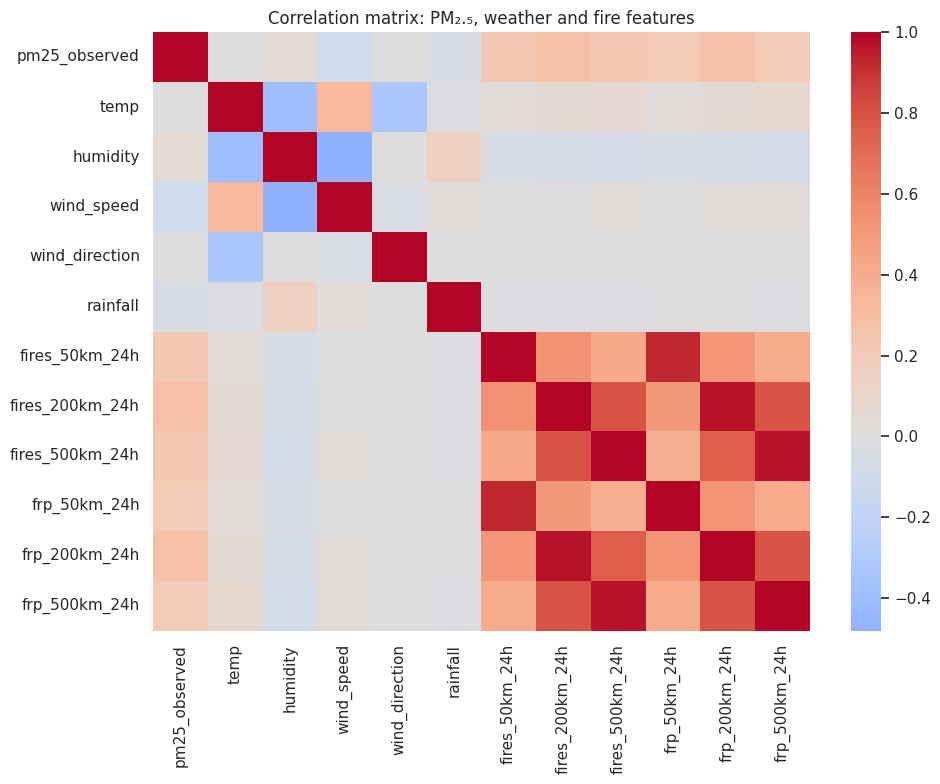

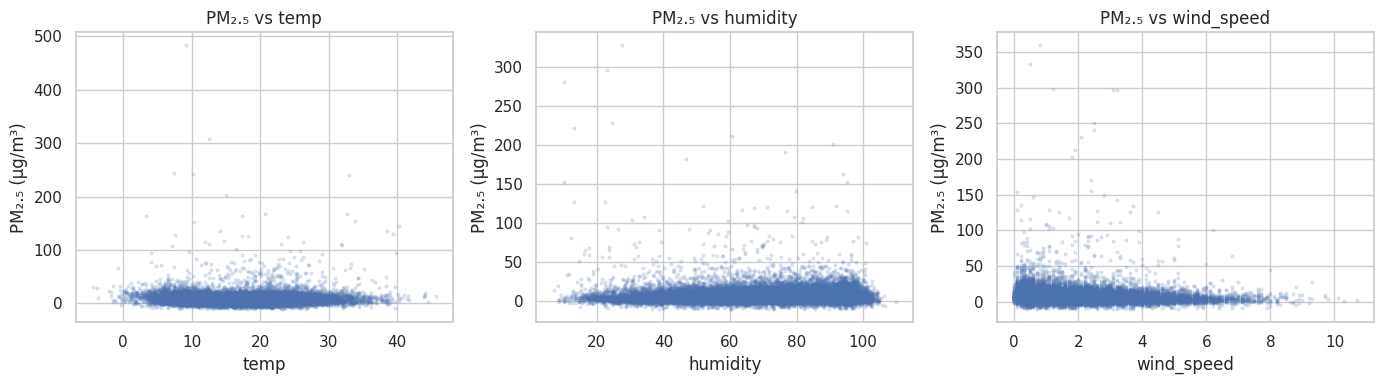

In [ ]:
corr_cols = [c for c in ["pm25_observed","temp","humidity","wind_speed","wind_direction","rainfall",
                         "fires_50km_24h","fires_200km_24h","fires_500km_24h",
                         "frp_50km_24h","frp_200km_24h","frp_500km_24h"] if c in df_model.columns]
corr = df_model[corr_cols].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(10, 8))
if sns is not None:
    sns.heatmap(corr, cmap="coolwarm", center=0, annot=False, ax=ax)
else:
    im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=90)
    ax.set_yticks(range(len(corr.index)), corr.index)
    fig.colorbar(im, ax=ax)
ax.set_title("Correlation matrix: PM₂.₅, weather and fire features")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["temp","humidity","wind_speed"]):
    if col in df_model:
        sample = df_model[["pm25_observed",col]].dropna()
        if len(sample) > 30000:
            sample = sample.sample(30000, random_state=RANDOM_STATE)
        ax.scatter(sample[col], sample["pm25_observed"], s=4, alpha=.15)
        ax.set(xlabel=col, ylabel="PM₂.₅ (µg/m³)", title=f"PM₂.₅ vs {col}")
fig.tight_layout()
plt.show()

In [ ]:

del df_hot, df_hot_raw
gc.collect()
print("Released raw hotspot tables after feature generation; compact fire features and model table are retained.")


Released raw hotspot tables after feature generation; compact fire features and model table are retained.


Prediction target:
Target Definition
The prediction target is a binary indicator representing whether PM₂.₅ exceeds the selected threshold during the following 24 hours.

Threshold and Class Distribution
The threshold should be justified using an appropriate air-quality guideline or project requirement, with units stated clearly. The positive and negative class counts are examined to identify class imbalance. Incomplete future observation windows require explicit handling.


In [ ]:

THRESHOLD_PM25 = 15.0  # µg/m³; WHO 2021 24-hour guideline benchmark
MIN_FUTURE_OBSERVATIONS = 18  # at least 75% coverage of a 24-hour forecast window
df_model["future_24h_mean_pm25"] = np.nan
for station, idx in df_model.groupby("station", sort=False).groups.items():
    part = df_model.loc[idx].sort_values("datetime")
    times = part["datetime"].to_numpy(dtype="datetime64[ns]")
    values = pd.to_numeric(part["pm25_observed"], errors="coerce").to_numpy(dtype=float)
    valid = np.isfinite(values)
    csum = np.r_[0.0, np.cumsum(np.where(valid, values, 0.0))]
    ccount = np.r_[0, np.cumsum(valid.astype(int))]
    right = np.searchsorted(times, times + np.timedelta64(24, "h"), side="right")
    starts = np.arange(len(times)) + 1
    sums = csum[right] - csum[starts]
    counts = ccount[right] - ccount[starts]
    means = np.divide(sums, counts, out=np.full(len(times), np.nan), where=counts >= MIN_FUTURE_OBSERVATIONS)
    df_model.loc[part.index, "future_24h_mean_pm25"] = means
df_model["next24_exceedance"] = np.where(
    df_model["future_24h_mean_pm25"].notna(),
    (df_model["future_24h_mean_pm25"] > THRESHOLD_PM25).astype(int),
    np.nan
)
labelled = df_model.dropna(subset=["next24_exceedance"]).copy()
labelled["next24_exceedance"] = labelled["next24_exceedance"].astype(int)
print(f"Target: mean observed PM₂.₅ in (t, t+24h] > {THRESHOLD_PM25} µg/m³.")
print(f"Minimum valid future observations: {MIN_FUTURE_OBSERVATIONS} of 24.")
print("Target-labelled rows:", f"{len(labelled):,}")
print("Positive exceedance prevalence:", f"{labelled['next24_exceedance'].mean():.2%}")
display(labelled[["station","datetime","pm25_observed","future_24h_mean_pm25","next24_exceedance"]].head(10))


Target: mean observed PM₂.₅ in (t, t+24h] > 15.0 µg/m³.
Minimum valid future observations: 18 of 24.
Target-labelled rows: 469,726
Positive exceedance prevalence: 4.66%


,station,datetime,pm25_observed,future_24h_mean_pm25,next24_exceedance
26,Earlwood,2016-01-02 04:00:00,NaN,10.583333,0
27,Earlwood,2016-01-02 05:00:00,-2.2,10.900000,0
28,Earlwood,2016-01-02 06:00:00,7.9,11.822222,0
29,Earlwood,2016-01-02 07:00:00,12.8,12.677778,0
30,Earlwood,2016-01-02 08:00:00,10.5,13.500000,0
31,Earlwood,2016-01-02 09:00:00,0.6,14.100000,0
32,Earlwood,2016-01-02 10:00:00,7.7,14.494444,0
33,Earlwood,2016-01-02 11:00:00,23.7,13.711111,0
39,Earlwood,2016-01-02 17:00:00,NaN,14.088889,0
40,Earlwood,2016-01-02 18:00:00,13.3,13.794444,0


Models:
1. Logistic Regression

Logistic Regression provides a baseline classifier that estimates the probability of an exceedance.

2. Random Forest

Random Forest combines multiple decision trees and can capture nonlinear relationships and interactions between features.

3. XGBoost and LightGBM

XGBoost and LightGBM are gradient-boosting algorithms that build ensembles of decision trees. They can model complex patterns in environmental data.

4. Model Comparison

The candidate models are compared using validation metrics. The preferred model should balance exceedance detection, false alarms, and probability reliability rather than rely on a single metric.


In [ ]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
    "Random Forest": RandomForestClassifier(n_estimators=35, min_samples_leaf=5, class_weight="balanced_subsample", n_jobs=4, random_state=RANDOM_STATE)
}
try:
    from xgboost import XGBClassifier
    models["XGBoost"] = XGBClassifier(n_estimators=100, max_depth=4, learning_rate=0.05, subsample=0.85, colsample_bytree=0.85, reg_lambda=1.0, eval_metric="logloss", n_jobs=4, random_state=RANDOM_STATE)
except ImportError:
    print("XGBoost unavailable; skipped.")
try:
    from lightgbm import LGBMClassifier
    models["LightGBM"] = LGBMClassifier(n_estimators=100, learning_rate=0.05, num_leaves=31, class_weight="balanced", verbosity=-1, random_state=RANDOM_STATE, n_jobs=4)
except ImportError:
    print("LightGBM unavailable; skipped.")
print("Models configured:", ", ".join(models))
display(pd.DataFrame({"model": list(models)}))


Models configured: Logistic Regression, Random Forest, XGBoost, LightGBM


,model
0,Logistic Regression
1,Random Forest
2,XGBoost
3,LightGBM


Chronological splitting:

1. Time-Based Evaluation

The data are divided chronologically into training, validation, and test sets. Earlier observations are used for training, validation data support model selection, and later held-out observations provide an independent evaluation.

2. Leakage Prevention

Preprocessing and feature engineering must respect the chronological split. This design more closely represents forecasting future conditions from historical observations.


In [ ]:
feature_cols = [
    "temp_prev","humidity_prev","wind_speed_prev","rainfall_prev","wind_direction_prev",
    "pm25_lag_1h","pm25_lag_3h","pm25_lag_6h","pm25_lag_12h","pm25_lag_24h",
    "pm25_mean_prev_6h","pm25_mean_prev_12h","pm25_mean_prev_24h",
    "fires_50km_24h","fires_100km_24h","fires_200km_24h","fires_500km_24h",
    "frp_50km_24h","frp_100km_24h","frp_200km_24h","frp_500km_24h",
    "nearest_fire_km_24h","hour","month","day_of_week","sin_hour","cos_hour","sin_month","cos_month"
]
feature_cols = [c for c in feature_cols if c in labelled.columns]
# One-hot encode station as a categorical predictor, preserving train/test time ordering.
data = labelled[["datetime","station","next24_exceedance"] + feature_cols].copy()
data = pd.get_dummies(data, columns=["station"], prefix="station", dtype=int)
station_dummy_cols = [c for c in data.columns if c.startswith("station_")]
model_features = feature_cols + station_dummy_cols

# Replace infinities, then impute predictors using training medians only.
data[model_features] = data[model_features].replace([np.inf,-np.inf], np.nan)
unique_times = np.array(sorted(data["datetime"].unique()))
if len(unique_times) < 100:
    raise ValueError("Too few labelled timestamps for a reliable chronological train/validation/test split.")
train_cut = unique_times[int(len(unique_times)*0.70)]
valid_cut = unique_times[int(len(unique_times)*0.85)]
train_mask = data["datetime"] < train_cut
valid_mask = (data["datetime"] >= train_cut) & (data["datetime"] < valid_cut)
test_mask = data["datetime"] >= valid_cut

X_train_raw, y_train = data.loc[train_mask, model_features], data.loc[train_mask, "next24_exceedance"].astype(int)
X_valid_raw, y_valid = data.loc[valid_mask, model_features], data.loc[valid_mask, "next24_exceedance"].astype(int)
X_test_raw, y_test = data.loc[test_mask, model_features], data.loc[test_mask, "next24_exceedance"].astype(int)

medians = X_train_raw.median(numeric_only=True).fillna(0)
X_train = X_train_raw.fillna(medians).fillna(0)
X_valid = X_valid_raw.fillna(medians).fillna(0)
X_test = X_test_raw.fillna(medians).fillna(0)

print("Train:", X_train.shape, X_train.index.min(), X_train.index.max())
print("Validation:", X_valid.shape, X_valid.index.min(), X_valid.index.max())
print("Test:", X_test.shape, X_test.index.min(), X_test.index.max())
print("Features:", len(model_features))
print("Positive rates:", {"train": y_train.mean(), "validation": y_valid.mean(), "test": y_test.mean()})

Train: (324553, 35) 26 469119
Validation: (72484, 35) 58110 481719
Test: (72689, 35) 70710 494320
Features: 35
Positive rates: {'train': np.float64(0.05720175133183178), 'validation': np.float64(0.02738535400916064), 'test': np.float64(0.018200828185832796)}


In [ ]:

# Reproducible training-period sample keeps fitting practical; validation and test sets remain complete.
train_sample_idx = X_train.sample(n=min(80000, len(X_train)), random_state=RANDOM_STATE).index
X_train_fit = X_train.loc[train_sample_idx]
y_train_fit = y_train.loc[train_sample_idx]
if "XGBoost" in models:
    pos = max(1, int((y_train_fit == 1).sum()))
    neg = max(1, int((y_train_fit == 0).sum()))
    models["XGBoost"].set_params(scale_pos_weight=neg / pos)

fitted_models = {}
validation_probabilities = {}
fit_summary = []
for name, model in models.items():
    print("Fitting", name)
    model.fit(X_train_fit, y_train_fit)
    fitted_models[name] = model
    validation_probabilities[name] = model.predict_proba(X_valid)[:, 1]
    fit_summary.append({"model": name, "training_rows": len(X_train_fit), "training_positive_rate": float(y_train_fit.mean()), "validation_rows": len(X_valid), "validation_positive_rate": float(y_valid.mean())})
display(pd.DataFrame(fit_summary))


Fitting Logistic Regression
Fitting Random Forest
Fitting XGBoost
Fitting LightGBM


,model,training_rows,training_positive_rate,validation_rows,validation_positive_rate
0,Logistic Regression,80000,0.0572,72484,0.027385
1,Random Forest,80000,0.0572,72484,0.027385
2,XGBoost,80000,0.0572,72484,0.027385
3,LightGBM,80000,0.0572,72484,0.027385


 Evaluation:
 1. Precision, Recall, and F1 Score

Precision measures how many predicted exceedances are correct. Recall measures how many actual exceedances are detected. The F1 score summarises the balance between precision and recall.

2. AUROC and Brier Score

AUROC measures the model’s ability to rank positive cases above negative cases across decision thresholds. The Brier score measures the accuracy of predicted probabilities, with lower values indicating better probabilistic performance.

3. False-Alarm Rate

The false-alarm rate measures how often the model predicts an exceedance that is not observed. This metric helps assess the practical consequences of issuing incorrect warnings.


In [ ]:

from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             brier_score_loss, confusion_matrix, roc_curve, precision_recall_curve)
def metric_row(y_true, prob, cutoff=0.5):
    pred=(np.asarray(prob)>=cutoff).astype(int)
    tn,fp,fn,tp=confusion_matrix(y_true,pred,labels=[0,1]).ravel()
    return {"precision":precision_score(y_true,pred,zero_division=0),
            "recall":recall_score(y_true,pred,zero_division=0),
            "F1":f1_score(y_true,pred,zero_division=0),
            "AUROC":roc_auc_score(y_true,prob) if pd.Series(y_true).nunique()==2 else np.nan,
            "Brier score":brier_score_loss(y_true,prob),
            "false-alarm rate":fp/(fp+tn) if fp+tn else np.nan,
            "TN":tn,"FP":fp,"FN":fn,"TP":tp}
validation_metrics=pd.DataFrame({name:metric_row(y_valid,prob) for name,prob in validation_probabilities.items()}).T.sort_values("F1",ascending=False)
display(validation_metrics.round(4))
fig,ax=plt.subplots(figsize=(9,4))
validation_metrics[["precision","recall","F1","AUROC"]].plot(kind="bar",ax=ax)
ax.set(title="Validation performance at probability cutoff 0.5",ylabel="Score",ylim=(0,1))
ax.tick_params(axis="x",rotation=25); fig.tight_layout(); plt.show()
fig,ax=plt.subplots(figsize=(7,6))
for name,prob in validation_probabilities.items():
    if pd.Series(y_valid).nunique()==2:
        fpr,tpr,_=roc_curve(y_valid,prob)
        ax.plot(fpr,tpr,label=f"{name} (AUC={roc_auc_score(y_valid,prob):.3f})")
ax.plot([0,1],[0,1],linestyle="--",color="grey")
ax.set(title="Validation ROC curves",xlabel="False positive rate",ylabel="True positive rate")
ax.legend(); fig.tight_layout(); plt.show()
best_name = validation_metrics.index[0]
best_model = fitted_models[best_name]
print("Validation-selected model:", best_name)


,precision,recall,F1,AUROC,Brier score,false-alarm rate,TN,FP,FN,TP
Random Forest,0.2903,0.3542,0.3190,0.9109,0.0360,0.0244,68780.0,1719.0,1282.0,703.0
LightGBM,0.1433,0.8131,0.2436,0.9251,0.0936,0.1369,60847.0,9652.0,371.0,1614.0
XGBoost,0.1202,0.8237,0.2098,0.9150,0.1146,0.1697,58533.0,11966.0,350.0,1635.0
Logistic Regression,0.1131,0.8625,0.2000,0.9182,0.1397,0.1904,57073.0,13426.0,273.0,1712.0


Validation-selected model: Random Forest


 Model visualisations

1. Confusion Matrices and ROC Curves

Confusion matrices show correct and incorrect classifications. ROC curves illustrate the trade-off between detecting exceedances and generating false positives across different thresholds.

2. Performance Comparison

Comparison charts provide a visual summary of model performance. They help identify trade-offs relevant to the early-warning objective.


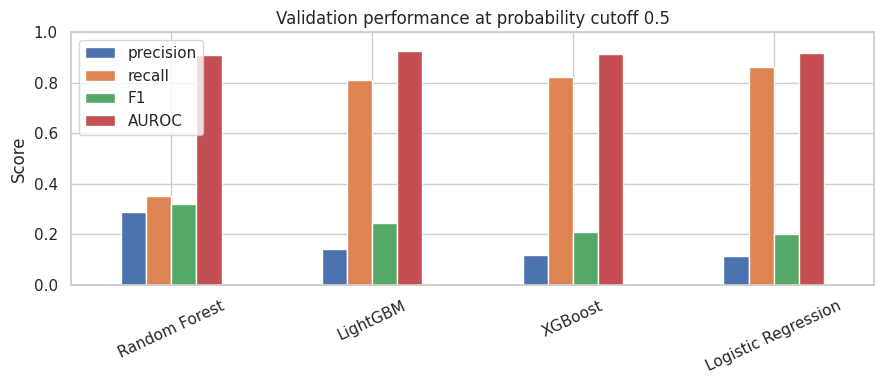

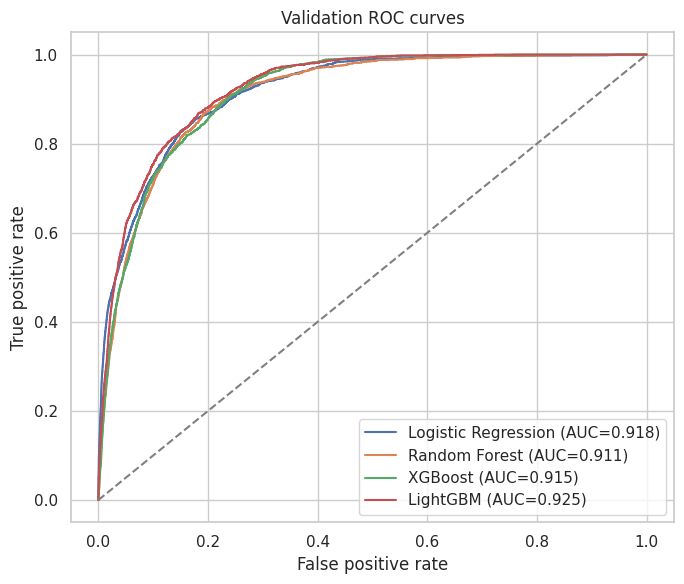

In [ ]:

from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             brier_score_loss, confusion_matrix, roc_curve, precision_recall_curve)
def metric_row(y_true, prob, cutoff=0.5):
    pred=(np.asarray(prob)>=cutoff).astype(int)
    tn,fp,fn,tp=confusion_matrix(y_true,pred,labels=[0,1]).ravel()
    return {"precision":precision_score(y_true,pred,zero_division=0),
            "recall":recall_score(y_true,pred,zero_division=0),
            "F1":f1_score(y_true,pred,zero_division=0),
            "AUROC":roc_auc_score(y_true,prob) if pd.Series(y_true).nunique()==2 else np.nan,
            "Brier score":brier_score_loss(y_true,prob),
            "false-alarm rate":fp/(fp+tn) if fp+tn else np.nan,
            "TN":tn,"FP":fp,"FN":fn,"TP":tp}
validation_metrics=pd.DataFrame({name:metric_row(y_valid,prob) for name,prob in validation_probabilities.items()}).T.sort_values("F1",ascending=False)
display(validation_metrics.round(4))
fig,ax=plt.subplots(figsize=(9,4))
validation_metrics[["precision","recall","F1","AUROC"]].plot(kind="bar",ax=ax)
ax.set(title="Validation performance at probability cutoff 0.5",ylabel="Score",ylim=(0,1))
ax.tick_params(axis="x",rotation=25); fig.tight_layout(); plt.show()
fig,ax=plt.subplots(figsize=(7,6))
for name,prob in validation_probabilities.items():
    if pd.Series(y_valid).nunique()==2:
        fpr,tpr,_=roc_curve(y_valid,prob)
        ax.plot(fpr,tpr,label=f"{name} (AUC={roc_auc_score(y_valid,prob):.3f})")
ax.plot([0,1],[0,1],linestyle="--",color="grey")
ax.set(title="Validation ROC curves",xlabel="False positive rate",ylabel="True positive rate")
ax.legend(); fig.tight_layout(); plt.show()


Explainability


1. Feature Importance

Feature-importance analysis identifies variables that contribute to model predictions according to the selected importance measure.

2. SHAP Analysis

SHAP values explain how individual features contribute to predictions relative to a reference prediction. Summary plots help identify influential features and their relationships with model outputs.

3. Limitations

Feature importance and SHAP reveal predictive associations, not proof of causation. Their interpretation should consider correlated features, data quality, and model limitations.


,feature,importance_mean,importance_std
11,pm25_mean_prev_12h,0.0220,0.0022
12,pm25_mean_prev_24h,0.0156,0.0051
18,frp_100km_24h,0.0082,0.0013
24,day_of_week,0.0068,0.0030
6,pm25_lag_3h,0.0062,0.0026
0,temp_prev,0.0046,0.0008
8,pm25_lag_12h,0.0044,0.0009
5,pm25_lag_1h,0.0042,0.0014
16,fires_500km_24h,0.0036,0.0001
1,humidity_prev,0.0035,0.0002


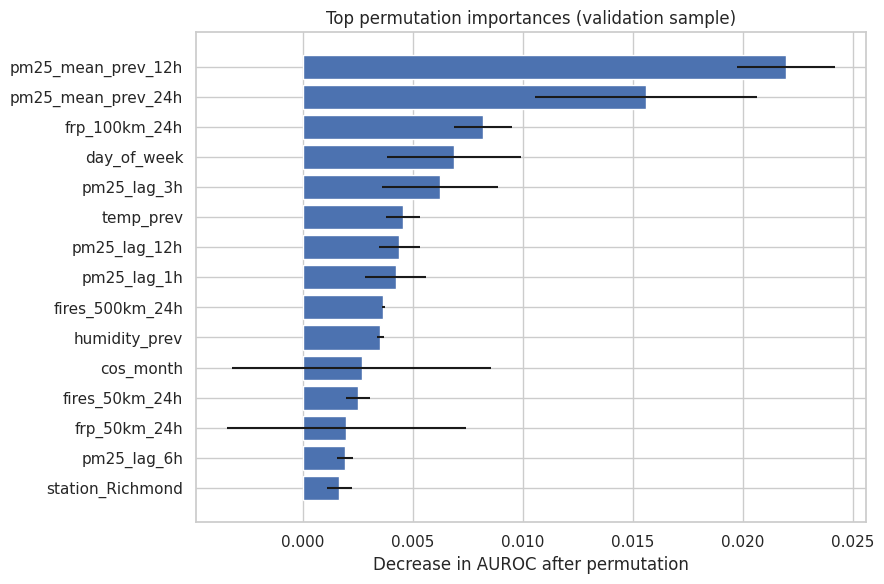

In [ ]:

from sklearn.inspection import permutation_importance
sample_n=min(1200,len(X_valid))
rng=np.random.default_rng(RANDOM_STATE)
sample_idx=rng.choice(len(X_valid),size=sample_n,replace=False)
X_imp=X_valid.iloc[sample_idx]; y_imp=y_valid.iloc[sample_idx]
perm=permutation_importance(best_model,X_imp,y_imp,n_repeats=2,random_state=RANDOM_STATE,scoring="roc_auc",n_jobs=1)
importance=pd.DataFrame({"feature":model_features,"importance_mean":perm.importances_mean,"importance_std":perm.importances_std}).sort_values("importance_mean",ascending=False)
display(importance.head(20).round(4))
fig,ax=plt.subplots(figsize=(9,6))
top=importance.head(15).sort_values("importance_mean")
ax.barh(top["feature"],top["importance_mean"],xerr=top["importance_std"])
ax.set(title="Top permutation importances (validation sample)",xlabel="Decrease in AUROC after permutation")
fig.tight_layout(); plt.show()


SHAP completed on 100 validation rows.


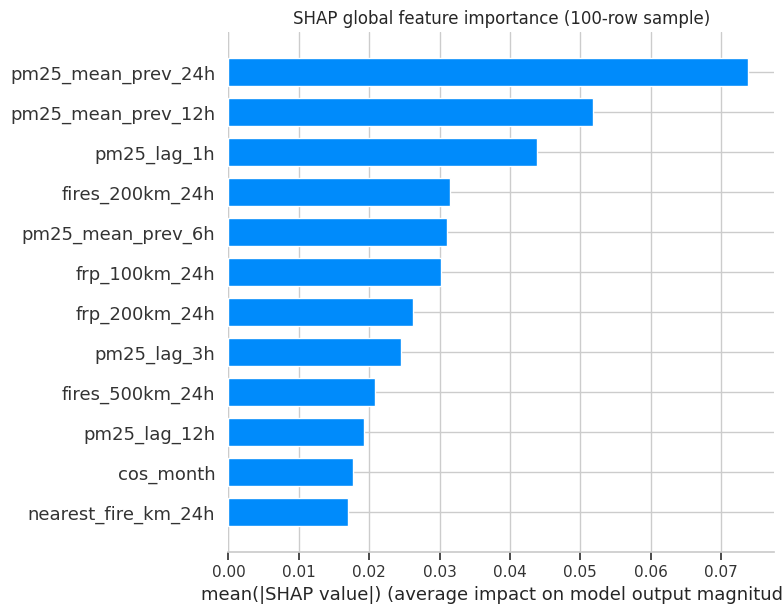

In [ ]:

try:
    import shap
    shap_n=min(100,len(X_valid))
    X_shap=X_valid.sample(shap_n,random_state=RANDOM_STATE)
    base_model=best_model[-1] if hasattr(best_model,"named_steps") else best_model
    explainer=shap.TreeExplainer(base_model)
    shap_values=explainer.shap_values(X_shap)
    if isinstance(shap_values,list): shap_values=shap_values[-1]
    if isinstance(shap_values,np.ndarray) and shap_values.ndim==3: shap_values=shap_values[:,:,1]
    shap.summary_plot(shap_values,X_shap,plot_type="bar",show=False,max_display=12)
    plt.title("SHAP global feature importance (100-row sample)")
    plt.tight_layout(); plt.show()
    print("SHAP completed on",shap_n,"validation rows.")
except Exception as exc:
    print("SHAP could not be computed in this environment:",type(exc).__name__,str(exc)[:300])
    print("Permutation importance above remains the reported explainability result.")


Calibration:

1. Probability Reliability

Calibration examines whether predicted probabilities correspond to observed event frequencies. For example, a well-calibrated group of predictions near 0.70 should experience the event approximately 70% of the time over a sufficiently large sample.

2. Calibration Curve and Brier Score

Calibration curves compare predicted probabilities with observed frequencies. The Brier score provides a numerical measure of probabilistic error. Calibration procedures should use validation data rather than the final test set.


Selected model from validation: Random Forest
Raw validation Brier: 0.036
Calibrated validation Brier: 0.0228
Validation-selected binary alert threshold: 0.15


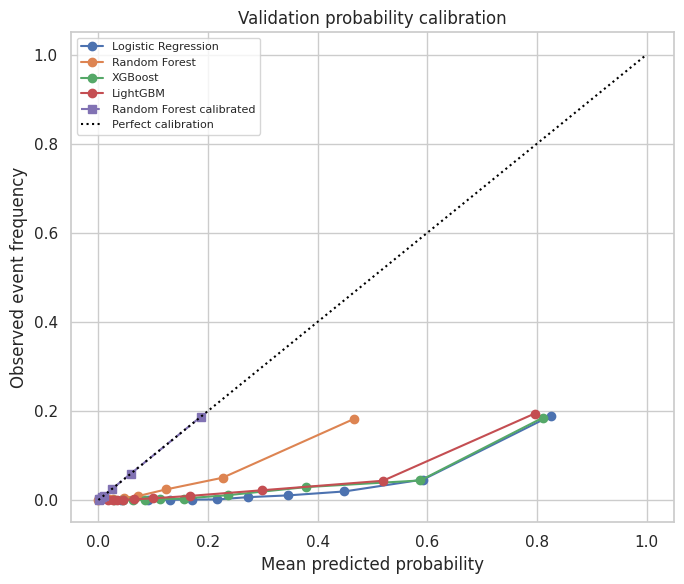

,threshold,precision,recall,F1,AUROC,Brier score,false-alarm rate,TN,FP,FN,TP
10,0.15,0.2729,0.4383,0.3364,0.9121,0.0228,0.0329,68181,2318,1115,870
12,0.17,0.2729,0.4383,0.3364,0.9121,0.0228,0.0329,68181,2318,1115,870
11,0.16,0.2729,0.4383,0.3364,0.9121,0.0228,0.0329,68181,2318,1115,870
14,0.19,0.2729,0.4383,0.3364,0.9121,0.0228,0.0329,68181,2318,1115,870
13,0.18,0.2729,0.4383,0.3364,0.9121,0.0228,0.0329,68181,2318,1115,870


In [ ]:

from sklearn.calibration import calibration_curve
from sklearn.isotonic import IsotonicRegression
best_name=validation_metrics.index[0]
best_model=fitted_models[best_name]
best_valid_prob=np.asarray(validation_probabilities[best_name])
calibrator=None
if len(y_valid)>=100 and pd.Series(y_valid).nunique()==2:
    calibrator=IsotonicRegression(out_of_bounds="clip")
    calibrator.fit(best_valid_prob,y_valid)
    calibrated_valid_prob=calibrator.predict(best_valid_prob)
else:
    calibrated_valid_prob=best_valid_prob
    print("Validation data insufficient for isotonic calibration; using raw model probabilities.")
fig,ax=plt.subplots(figsize=(7,6))
for name,prob in validation_probabilities.items():
    frac_pos,mean_pred=calibration_curve(y_valid,prob,n_bins=10,strategy="quantile")
    ax.plot(mean_pred,frac_pos,marker="o",label=name)
frac_pos,mean_pred=calibration_curve(y_valid,calibrated_valid_prob,n_bins=10,strategy="quantile")
ax.plot(mean_pred,frac_pos,marker="s",linestyle="--",label=f"{best_name} calibrated")
ax.plot([0,1],[0,1],linestyle=":",color="black",label="Perfect calibration")
ax.set(title="Validation probability calibration",xlabel="Mean predicted probability",ylabel="Observed event frequency")
ax.legend(fontsize=8); fig.tight_layout(); plt.show()
print("Selected model from validation:",best_name)
print("Raw validation Brier:",round(brier_score_loss(y_valid,best_valid_prob),4))
print("Calibrated validation Brier:",round(brier_score_loss(y_valid,calibrated_valid_prob),4))
threshold_grid=np.linspace(0.05,0.95,91)
threshold_scores=[{"threshold":float(t),**metric_row(y_valid,calibrated_valid_prob,cutoff=float(t))} for t in threshold_grid]
threshold_table=pd.DataFrame(threshold_scores)
chosen_threshold=float(threshold_table.sort_values(["F1","recall"],ascending=False).iloc[0]["threshold"])
print("Validation-selected binary alert threshold:",round(chosen_threshold,3))
display(threshold_table.sort_values("F1",ascending=False).head(5).round(4))


,precision,recall,F1,AUROC,Brier score,false-alarm rate,TN,FP,FN,TP
Random Forest,0.2333,0.2872,0.2575,0.8929,0.0162,0.0175,70117,1249,943,380


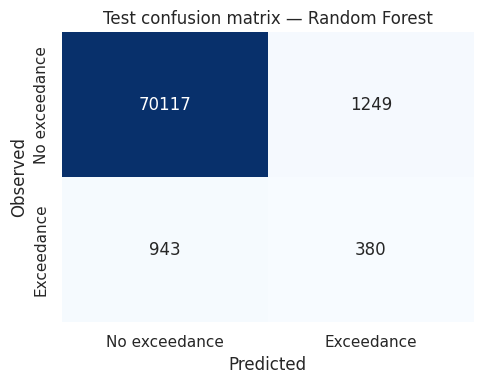

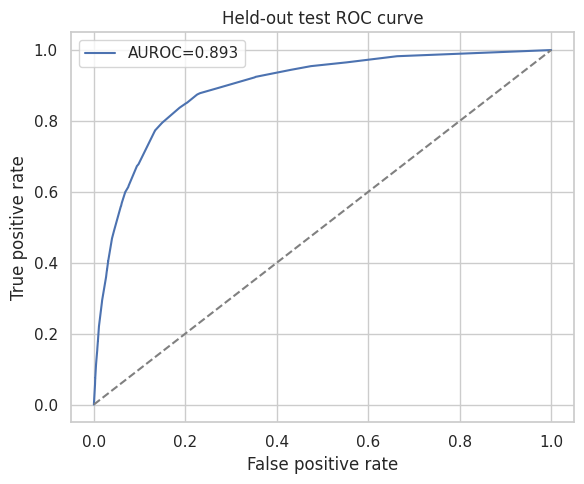

In [ ]:

test_raw_prob=best_model.predict_proba(X_test)[:,1]
test_prob=calibrator.predict(test_raw_prob) if calibrator is not None else test_raw_prob
test_metrics=metric_row(y_test,test_prob,cutoff=chosen_threshold)
display(pd.DataFrame([test_metrics],index=[best_name]).round(4))
cm=confusion_matrix(y_test,(test_prob>=chosen_threshold).astype(int),labels=[0,1])
fig,ax=plt.subplots(figsize=(5,4))
try:
 import seaborn as sns
 sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",cbar=False,xticklabels=["No exceedance","Exceedance"],yticklabels=["No exceedance","Exceedance"],ax=ax)
except ImportError:
 ax.imshow(cm)
 for i in range(2):
  for j in range(2): ax.text(j,i,str(cm[i,j]),ha="center",va="center")
ax.set(title=f"Test confusion matrix — {best_name}",xlabel="Predicted",ylabel="Observed")
fig.tight_layout(); plt.show()
fpr,tpr,_=roc_curve(y_test,test_prob)
fig,ax=plt.subplots(figsize=(6,5))
ax.plot(fpr,tpr,label=f"AUROC={roc_auc_score(y_test,test_prob):.3f}")
ax.plot([0,1],[0,1],linestyle="--",color="grey")
ax.set(title="Held-out test ROC curve",xlabel="False positive rate",ylabel="True positive rate")
ax.legend(); fig.tight_layout(); plt.show()


Warnings:

1. Warning Categories

Predicted probabilities are mapped into four categories: Low, Moderate, High, and Extreme. The numerical boundaries must be explicitly defined and justified in the notebook.

2. Interpretation

Low indicates a comparatively lower estimated probability of exceedance, while Moderate, High, and Extreme represent progressively higher probability ranges. These categories are project-defined unless they follow an established official framework.

3. Limitations

Warnings are estimates rather than guarantees. They should support, not replace, official air-quality monitoring and public-health advice.


In [ ]:
def risk_label(p):
    if pd.isna(p): return "Unavailable"
    if p < 0.20: return "Low"
    if p < 0.40: return "Moderate"
    if p < 0.70: return "High"
    return "Extreme"

# Latest feature-complete rows per station, excluding rows without any model features.
latest_source = df_model[df_model["datetime"] <= HOTSPOT_DATA_END].sort_values("datetime").copy()
latest_source = latest_source.dropna(subset=["pm25_lag_1h"])
latest_rows = latest_source.groupby("station", as_index=False).tail(1).copy()
latest_rows = pd.get_dummies(latest_rows, columns=["station"], prefix="station", dtype=int)
# Align dummy columns to the model matrix.
for col in model_features:
    if col not in latest_rows.columns:
        latest_rows[col] = 0
latest_X = latest_rows[model_features].replace([np.inf,-np.inf], np.nan).fillna(medians).fillna(0)
if len(latest_X):
    latest_raw_prob = best_model.predict_proba(latest_X)[:,1]
    latest_prob = calibrator.predict(latest_raw_prob) if calibrator is not None else latest_raw_prob
    latest_rows["warning_probability"] = latest_prob
    latest_rows["risk_level"] = latest_rows["warning_probability"].map(risk_label)
    latest_rows["warning_threshold_met"] = latest_rows["warning_probability"] >= chosen_threshold
    station_cols = [c for c in latest_rows.columns if c.startswith("station_")]
    # Recover station name from the one-hot encoded row.
    latest_rows["station_name"] = latest_rows[station_cols].idxmax(axis=1).str.replace("station_","",regex=False)
    dashboard_cols = ["station_name","datetime","warning_probability","risk_level","warning_threshold_met"]
    display(latest_rows[dashboard_cols].sort_values("warning_probability", ascending=False).round(4))
else:
    print("No station has a feature-complete latest row; dashboard cannot be generated.")

,station_name,datetime,warning_probability,risk_level,warning_threshold_met
323063,Richmond,2025-07-14 06:00:00,0.0456,Low,False
163420,Liverpool,2025-07-14 06:00:00,0.0347,Low,False
79401,Earlwood,2025-07-14 06:00:00,0.0222,Low,False
247439,Newcastle,2025-07-14 06:00:00,0.0045,Low,False
406392,Wollongong,2025-07-14 06:00:00,0.0012,Low,False
490411,Wyong,2025-07-14 06:00:00,0.0003,Low,False


Dashboard:
1. Dashboard Purpose

The dashboard brings together air-quality summaries, model evaluation results, predicted probabilities, station-level warnings, and relevant visualisations.

2. Practical Use

The dashboard helps communicate model results in an accessible format. Unless connected to regularly updated data and tested operationally, it should be considered a research prototype rather than a live warning service.


,station_name,datetime,warning_probability,risk_level,warning_threshold_met
323063,Richmond,2025-07-14 06:00:00,0.0456,Low,False
163420,Liverpool,2025-07-14 06:00:00,0.0347,Low,False
79401,Earlwood,2025-07-14 06:00:00,0.0222,Low,False
247439,Newcastle,2025-07-14 06:00:00,0.0045,Low,False
406392,Wollongong,2025-07-14 06:00:00,0.0012,Low,False
490411,Wyong,2025-07-14 06:00:00,0.0003,Low,False


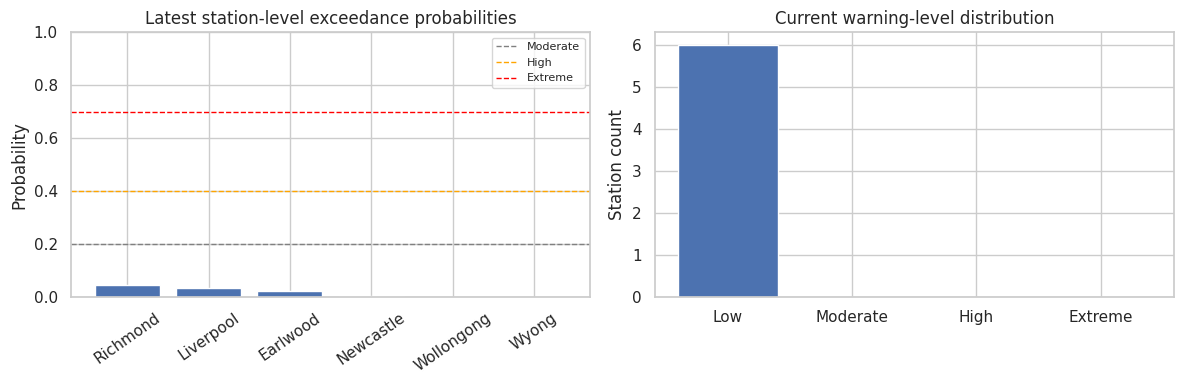

In [ ]:

dash = latest_rows[dashboard_cols].sort_values("warning_probability", ascending=False).copy()
display(dash.round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(dash["station_name"], dash["warning_probability"])
axes[0].axhline(0.20, linestyle="--", color="grey", linewidth=1, label="Moderate")
axes[0].axhline(0.40, linestyle="--", color="orange", linewidth=1, label="High")
axes[0].axhline(0.70, linestyle="--", color="red", linewidth=1, label="Extreme")
axes[0].set(title="Latest station-level exceedance probabilities", ylabel="Probability", ylim=(0, 1))
axes[0].tick_params(axis="x", rotation=35)
axes[0].legend(fontsize=8)
counts = dash["risk_level"].value_counts().reindex(["Low","Moderate","High","Extreme"], fill_value=0)
axes[1].bar(counts.index, counts.values)
axes[1].set(title="Current warning-level distribution", ylabel="Station count")
fig.tight_layout()
plt.show()


Discussion:
1. Main Findings

The project combines air-quality, hotspot, and station information to investigate pollution patterns and estimate future PM₂.₅ exceedance probabilities. The actual model metrics and visualisations should be used to identify the strongest findings and the selected model.

2. Limitations

Potential limitations include missing observations, uneven station coverage, incomplete meteorological information, uncertainty in hotspot matching, and changes in environmental conditions over time. Model performance may differ across locations and periods.

3. Future Improvements

Future work could incorporate weather forecasts, wind-driven smoke transport, additional monitoring locations, further temporal validation, and improved probability calibration. Independent testing is needed before operational deployment.



In [ ]:

print("Validation-selected model:", best_name)
print(f"Chronological held-out test rows: {len(y_test):,}")
print(f"Test event prevalence: {y_test.mean():.2%}")
print(f"Test AUROC: {test_metrics['AUROC']:.3f}")
print(f"Test precision / recall / F1: {test_metrics['precision']:.3f} / {test_metrics['recall']:.3f} / {test_metrics['F1']:.3f}")
print(f"Test Brier score: {test_metrics['Brier score']:.4f}")
print(f"Validation-selected alert threshold: {chosen_threshold:.2f}")
print("Model fitting used a reproducible 80,000-row sample from the training period; validation and test sets were kept complete.")
print(f"False-alarm rate: {test_metrics['false-alarm rate']:.2%}")
print("Interpretation: event prevalence changes across chronological partitions, so later-period performance may differ from validation.")
print("Limitations: only six NSW stations; satellite hotspots are imperfect fire proxies; missing hourly records require a minimum-coverage target; no causal inference.")
print("Latest hotspot observation available:", HOTSPOT_DATA_END)
print("Dashboard rows are restricted to timestamps with available hotspot coverage.")
print("Operational use: warnings are decision support and should be reviewed with official air-quality and emergency information.")


Validation-selected model: Random Forest
Chronological held-out test rows: 72,689
Test event prevalence: 1.82%
Test AUROC: 0.893
Test precision / recall / F1: 0.233 / 0.287 / 0.257
Test Brier score: 0.0162
Validation-selected alert threshold: 0.15
Model fitting used a reproducible 80,000-row sample from the training period; validation and test sets were kept complete.
False-alarm rate: 1.75%
Interpretation: event prevalence changes across chronological partitions, so later-period performance may differ from validation.
Limitations: only six NSW stations; satellite hotspots are imperfect fire proxies; missing hourly records require a minimum-coverage target; no causal inference.
Latest hotspot observation available: 2025-07-14 06:18:21
Dashboard rows are restricted to timestamps with available hotspot coverage.
Operational use: warnings are decision support and should be reviewed with official air-quality and emergency information.


Conclusion:
1. Project Summary

This project develops a framework for predicting the probability of PM₂.₅ threshold exceedance within the next 24 hours. It covers data preparation, exploratory analysis, the Black Summer case study, feature engineering, model development, evaluation, explainability, calibration, and warning categorisation.

2. Final Outcome

The resulting notebook demonstrates an approach to explainable wildfire-related air-quality early warning. Its practical usefulness depends on the measured test performance, the reliability of predicted probabilities, and the quality of available data.

3. Final Remarks

Further validation, reliable data updates, and operational testing are necessary before using the system for real-world warnings. The model should be treated as a decision-support prototype rather than a replacement for official forecasts or public-health guidance.


In [ ]:

print("FINAL RESULT")
print("Selected model:", best_name)
print(f"Forecast target: mean observed PM₂.₅ in the next 24 hours > {THRESHOLD_PM25:.1f} µg/m³")
print(f"Minimum future data coverage: {MIN_FUTURE_OBSERVATIONS}/24 observations")
print(f"Selected alert probability threshold: {chosen_threshold:.2f}")
print(f"Held-out test AUROC: {test_metrics['AUROC']:.3f}; F1: {test_metrics['F1']:.3f}; Brier: {test_metrics['Brier score']:.4f}")
print("Latest station warning rows:", len(latest_rows))
display(latest_rows[dashboard_cols].sort_values("warning_probability", ascending=False).round(4))


FINAL RESULT
Selected model: Random Forest
Forecast target: mean observed PM₂.₅ in the next 24 hours > 15.0 µg/m³
Minimum future data coverage: 18/24 observations
Selected alert probability threshold: 0.15
Held-out test AUROC: 0.893; F1: 0.257; Brier: 0.0162
Latest station warning rows: 6


,station_name,datetime,warning_probability,risk_level,warning_threshold_met
323063,Richmond,2025-07-14 06:00:00,0.0456,Low,False
163420,Liverpool,2025-07-14 06:00:00,0.0347,Low,False
79401,Earlwood,2025-07-14 06:00:00,0.0222,Low,False
247439,Newcastle,2025-07-14 06:00:00,0.0045,Low,False
406392,Wollongong,2025-07-14 06:00:00,0.0012,Low,False
490411,Wyong,2025-07-14 06:00:00,0.0003,Low,False


In [ ]:

OUTPUT_DIR.mkdir(exist_ok=True)
df_station_quality.to_csv(OUTPUT_DIR / "station_data_quality.csv", index=False)
df_black_summer_summary.to_csv(OUTPUT_DIR / "black_summer_summary.csv", index=False)
validation_metrics.to_csv(OUTPUT_DIR / "validation_model_comparison.csv")
pd.DataFrame([test_metrics], index=[best_name]).to_csv(OUTPUT_DIR / "heldout_test_metrics.csv")
latest_rows[dashboard_cols].to_csv(OUTPUT_DIR / "latest_station_warnings.csv", index=False)
df_model[["station", "datetime", "pm25_observed", "future_24h_mean_pm25", "next24_exceedance"]].to_csv(OUTPUT_DIR / "prediction_targets.csv", index=False)
print("Saved six CSV result files to:", OUTPUT_DIR.resolve())
print("Validation-selected model:", best_name)
print("Held-out test AUROC:", round(float(test_metrics["AUROC"]), 4))


Saved six CSV result files to: /mnt/data/outputs
Validation-selected model: Random Forest
Held-out test AUROC: 0.8929


In [ ]:
import sys
print("Python:", sys.version)
for package in ["pandas","numpy","matplotlib","scikit-learn","openpyxl","xgboost","lightgbm","shap"]:
    try:
        mod = __import__(package.replace("-", "_"))
        print(package, getattr(mod, "__version__", "installed"))
    except Exception:
        print(package, "not installed / unavailable")

Python: 3.13.5 (main, Jul 15 2026, 20:25:40) [GCC 14.2.0]
pandas 2.2.3
numpy 2.3.5
matplotlib 3.10.8
scikit-learn not installed / unavailable
openpyxl 3.1.5
xgboost 3.1.3
lightgbm 4.6.0
shap 0.50.0
